# Campaign 1: time-series EDA and LSTM remaining-range model

This notebook combines the original Campaign 1 train/test Parquet partitions, studies the telemetry, engineers chronological features per vehicle trip, and trains a sequence-to-one LSTM to estimate `remaining_range` in kilometres. Complete `(vehicle_id, trip_plan)` groups are kept in only one data split to prevent trip leakage.

In [1]:
from pathlib import Path
import json
import random

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
SEQUENCE_LENGTH = 30
SEQUENCE_STRIDE = 5
MAX_REASONABLE_RANGE_KM = 1000.0
MAX_TRAIN_SEQUENCES = 120_000
MAX_EVALUATION_SEQUENCES = 30_000

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)

In [2]:
def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "ev_battery_prediction").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


def load_parquet_parts(folder: Path) -> pd.DataFrame:
    files = sorted(
        file for file in folder.glob("*.parquet")
        if not file.name.startswith(".")
    )
    if not files:
        raise FileNotFoundError(f"No Parquet parts found in {folder}")
    return pd.concat(
        [pd.read_parquet(file) for file in files],
        ignore_index=True,
        sort=False,
    )


PROJECT_ROOT = find_project_root()
CAMPAIGN_ROOT = (
    PROJECT_ROOT / "ev_battery_prediction" / "data"
    / "output_data" / "campaign1"
)

campaign_parts = []
for partition in ("train", "test"):
    part = load_parquet_parts(CAMPAIGN_ROOT / f"{partition}_data.parquet")
    part["original_partition"] = partition
    campaign_parts.append(part)

raw_data = pd.concat(campaign_parts, ignore_index=True, sort=False)
print(f"Raw Campaign 1 shape: {raw_data.shape}")
display(raw_data.head())

Raw Campaign 1 shape: (672532, 14)


,vehicle_id,trip_plan,simulation_step,acceleration,actual_battery_capacity_wh,state_of_charge,speed,total_energy_consumed_wh,total_energy_regenerated_wh,completed_distance,traffic_factor,wind,remaining_range,original_partition
0,EV0,amurrio-durango,432.0,0.0,37817.921875,96.970001,62.224956,1847.280029,665.200012,5.956000,0.2,-4.1667,190.536041,train
1,EV0,amurrio-durango,488.0,0.0,37800.851562,96.930000,62.224956,2121.909912,922.760010,6.924000,0.2,-4.1667,218.251495,train
2,EV0,amurrio-durango,501.0,1.5,37726.218750,96.730003,83.824956,2211.510010,937.739990,7.163000,0.2,-4.1667,212.159637,train
3,EV0,amurrio-durango,555.0,0.0,37550.089844,96.279999,88.920229,2574.669922,1124.770020,8.497000,0.2,-4.1667,220.060257,train
4,EV0,amurrio-durango,904.0,0.0,35683.359375,91.500000,106.685067,5695.330078,2378.689941,16.759001,0.2,-4.1667,180.306396,train


In [19]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 672532 entries, 0 to 672531
Data columns (total 14 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   vehicle_id                   672532 non-null  str    
 1   trip_plan                    640347 non-null  str    
 2   simulation_step              640347 non-null  float64
 3   acceleration                 672532 non-null  float32
 4   actual_battery_capacity_wh   672532 non-null  float32
 5   state_of_charge              672532 non-null  float32
 6   speed                        672532 non-null  float64
 7   total_energy_consumed_wh     672532 non-null  float32
 8   total_energy_regenerated_wh  672532 non-null  float32
 9   completed_distance           672532 non-null  float32
 10  traffic_factor               672532 non-null  float64
 11  wind                         672532 non-null  float64
 12  remaining_range              672532 non-null  float32
 13  original_p

## Exploratory data analysis

In [3]:
KEY_COLUMNS = ["vehicle_id", "trip_plan", "simulation_step"]
TARGET_COLUMN = "remaining_range"
REQUIRED_COLUMNS = [
    *KEY_COLUMNS,
    "acceleration",
    "actual_battery_capacity_wh",
    "state_of_charge",
    "speed",
    "total_energy_consumed_wh",
    "total_energy_regenerated_wh",
    "completed_distance",
    "traffic_factor",
    "wind",
    TARGET_COLUMN,
]

missing_columns = sorted(set(REQUIRED_COLUMNS) - set(raw_data.columns))
if missing_columns:
    raise ValueError(f"Campaign 1 is missing columns: {missing_columns}")

quality_summary = pd.DataFrame({
    "metric": [
        "raw rows", "columns", "rows with complete keys",
        "unique vehicle IDs", "unique trip plans",
        "duplicate telemetry keys", "missing cells",
        "range above 1000 km",
    ],
    "value": [
        len(raw_data), len(raw_data.columns),
        int(raw_data[KEY_COLUMNS].notna().all(axis=1).sum()),
        raw_data["vehicle_id"].nunique(dropna=True),
        raw_data["trip_plan"].nunique(dropna=True),
        int(raw_data.dropna(subset=KEY_COLUMNS).duplicated(KEY_COLUMNS).sum()),
        int(raw_data[REQUIRED_COLUMNS].isna().sum().sum()),
        int((raw_data[TARGET_COLUMN] > MAX_REASONABLE_RANGE_KM).sum()),
    ],
})
display(quality_summary)
display(raw_data[REQUIRED_COLUMNS].describe(percentiles=[0.01, 0.5, 0.95, 0.99]).T)

,metric,value
0,raw rows,672532
1,columns,14
2,rows with complete keys,640347
3,unique vehicle IDs,18
4,unique trip plans,21
5,duplicate telemetry keys,0
6,missing cells,64370
7,range above 1000 km,10138


,count,mean,std,min,1%,50%,95%,99%,max
simulation_step,640347.0,1285.822691,829.091447,101.000000,139.000000,1147.000000,2840.000000,3671.000000,5.511000e+03
acceleration,672532.0,0.011246,0.852919,-8.324318,-3.500000,0.000000,1.500000,3.085380,3.500000e+00
actual_battery_capacity_wh,672532.0,50277.828125,18516.052734,17766.599609,20275.450117,52020.781250,77104.101172,79762.654922,7.999985e+04
state_of_charge,672532.0,85.757469,11.288715,55.000000,59.939999,88.120003,99.559998,99.940002,1.000000e+02
speed,672532.0,84.408796,32.000396,0.000000,0.000000,89.569178,129.642380,134.908745,1.376312e+02
total_energy_consumed_wh,672532.0,13331.949219,11490.942383,0.010000,65.959999,10600.834961,37415.878906,48425.504453,5.263574e+04
total_energy_regenerated_wh,672532.0,5322.220703,4964.000488,0.000000,11.063100,3984.325073,16395.500000,20940.380859,2.756346e+04
completed_distance,672532.0,26.665390,19.952333,0.000000,0.141000,22.830000,64.036003,78.283997,1.009141e+02
traffic_factor,672532.0,194.523858,395.600120,0.200000,0.200000,0.200000,1000.000000,1000.000000,1.000000e+03
wind,672532.0,-1.826765,1.587691,-4.166700,-4.166700,-1.944400,0.000000,0.000000,0.000000e+00


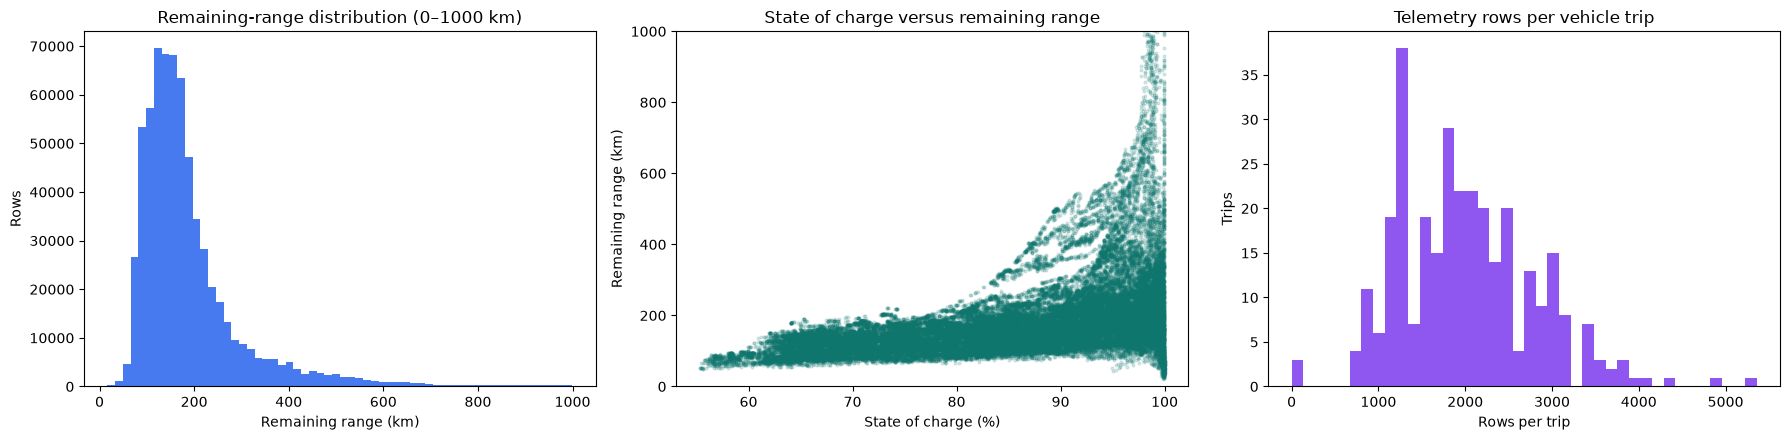

In [4]:
valid_range = raw_data.loc[
    raw_data[TARGET_COLUMN].between(0, MAX_REASONABLE_RANGE_KM),
    TARGET_COLUMN,
]
plot_sample = raw_data.sample(min(50_000, len(raw_data)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hist(valid_range, bins=60, color="#2563eb", alpha=0.85)
axes[0].set_title("Remaining-range distribution (0–1000 km)")
axes[0].set_xlabel("Remaining range (km)")
axes[0].set_ylabel("Rows")

axes[1].scatter(
    plot_sample["state_of_charge"], plot_sample[TARGET_COLUMN],
    s=4, alpha=0.15, color="#0f766e",
)
axes[1].set_ylim(0, MAX_REASONABLE_RANGE_KM)
axes[1].set_title("State of charge versus remaining range")
axes[1].set_xlabel("State of charge (%)")
axes[1].set_ylabel("Remaining range (km)")

rows_per_trip = (
    raw_data.dropna(subset=KEY_COLUMNS)
    .groupby(["vehicle_id", "trip_plan"])
    .size()
)
axes[2].hist(rows_per_trip, bins=40, color="#7c3aed", alpha=0.85)
axes[2].set_title("Telemetry rows per vehicle trip")
axes[2].set_xlabel("Rows per trip")
axes[2].set_ylabel("Trips")
plt.tight_layout()
plt.show()

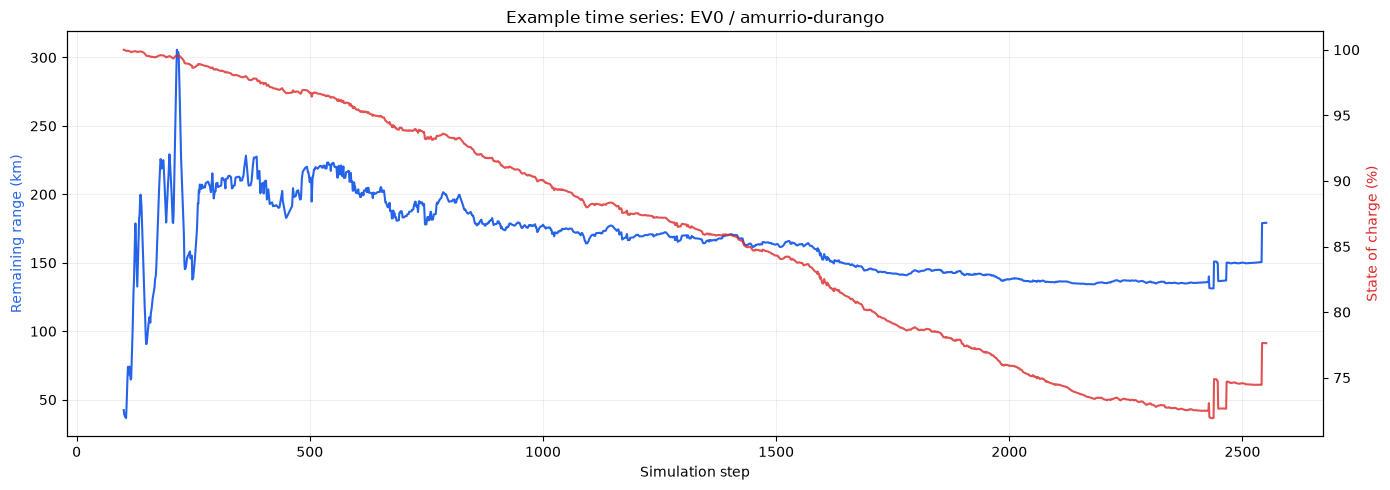

In [5]:
sample_keys = (
    raw_data.dropna(subset=KEY_COLUMNS)
    .loc[lambda frame: frame["vehicle_id"].astype(str).str.fullmatch(r"EV\d+")]
    [["vehicle_id", "trip_plan"]]
    .drop_duplicates()
    .iloc[0]
)
sample_trip = (
    raw_data.loc[
        (raw_data["vehicle_id"] == sample_keys["vehicle_id"])
        & (raw_data["trip_plan"] == sample_keys["trip_plan"])
    ]
    .sort_values("simulation_step")
)

fig, left_axis = plt.subplots(figsize=(14, 5))
right_axis = left_axis.twinx()
left_axis.plot(sample_trip["simulation_step"], sample_trip[TARGET_COLUMN],
               label="Remaining range", color="#2563eb")
right_axis.plot(sample_trip["simulation_step"], sample_trip["state_of_charge"],
                label="SOC", color="#dc2626", alpha=0.8)
left_axis.set_title(
    f"Example time series: {sample_keys['vehicle_id']} / {sample_keys['trip_plan']}"
)
left_axis.set_xlabel("Simulation step")
left_axis.set_ylabel("Remaining range (km)", color="#2563eb")
right_axis.set_ylabel("State of charge (%)", color="#dc2626")
left_axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Cleaning and time-series feature engineering

The original random train/test partition is recombined because it separates rows from the same trip. The model split below is rebuilt from complete vehicle trips. Invalid legacy rows, malformed vehicle IDs, non-finite values, and range estimates above the configurable physical ceiling are removed.

In [6]:
numeric_columns = [column for column in REQUIRED_COLUMNS if column not in {"vehicle_id", "trip_plan"}]
telemetry = raw_data[REQUIRED_COLUMNS].copy()
for column in numeric_columns:
    telemetry[column] = pd.to_numeric(telemetry[column], errors="coerce")

rows_before_cleaning = len(telemetry)
telemetry = telemetry.dropna(subset=REQUIRED_COLUMNS)
telemetry = telemetry.loc[telemetry["vehicle_id"].astype(str).str.fullmatch(r"EV\d+")].copy()
telemetry = telemetry.replace([np.inf, -np.inf], np.nan).dropna(subset=numeric_columns)
telemetry = telemetry.loc[telemetry[TARGET_COLUMN].between(0, MAX_REASONABLE_RANGE_KM)].copy()
telemetry = telemetry.drop_duplicates(KEY_COLUMNS, keep="first")
telemetry = telemetry.sort_values(KEY_COLUMNS).reset_index(drop=True)

GROUP_COLUMNS = ["vehicle_id", "trip_plan"]
grouped = telemetry.groupby(GROUP_COLUMNS, sort=False, observed=True)

telemetry["elapsed_time_s"] = grouped["simulation_step"].transform(lambda values: values - values.iloc[0])
telemetry["delta_time_s"] = grouped["simulation_step"].diff().fillna(0).clip(lower=0)
telemetry["distance_delta_km"] = grouped["completed_distance"].diff().fillna(0).clip(lower=0)
telemetry["energy_consumed_delta_wh"] = grouped["total_energy_consumed_wh"].diff().fillna(0).clip(lower=0)
telemetry["energy_regenerated_delta_wh"] = grouped["total_energy_regenerated_wh"].diff().fillna(0).clip(lower=0)
telemetry["net_energy_delta_wh"] = (
    telemetry["energy_consumed_delta_wh"]
    - telemetry["energy_regenerated_delta_wh"]
)
telemetry["battery_energy_kwh"] = telemetry["actual_battery_capacity_wh"] / 1000.0
telemetry["cumulative_net_energy_kwh"] = (
    telemetry["total_energy_consumed_wh"]
    - telemetry["total_energy_regenerated_wh"]
) / 1000.0
telemetry["absolute_acceleration"] = telemetry["acceleration"].abs()
telemetry["traffic_factor_log1p"] = np.log1p(telemetry["traffic_factor"].clip(lower=0))
telemetry["speed_rolling_mean_10"] = grouped["speed"].transform(
    lambda values: values.rolling(10, min_periods=1).mean()
)
telemetry["speed_rolling_std_10"] = grouped["speed"].transform(
    lambda values: values.rolling(10, min_periods=2).std().fillna(0)
)
telemetry["acceleration_rolling_abs_mean_10"] = grouped["acceleration"].transform(
    lambda values: values.abs().rolling(10, min_periods=1).mean()
)

print(f"Rows before cleaning: {rows_before_cleaning:,}")
print(f"Rows after cleaning:  {len(telemetry):,}")
print(f"Complete vehicle trips: {telemetry.groupby(GROUP_COLUMNS).ngroups:,}")

Rows before cleaning: 672,532
Rows after cleaning:  630,206
Complete vehicle trips: 315


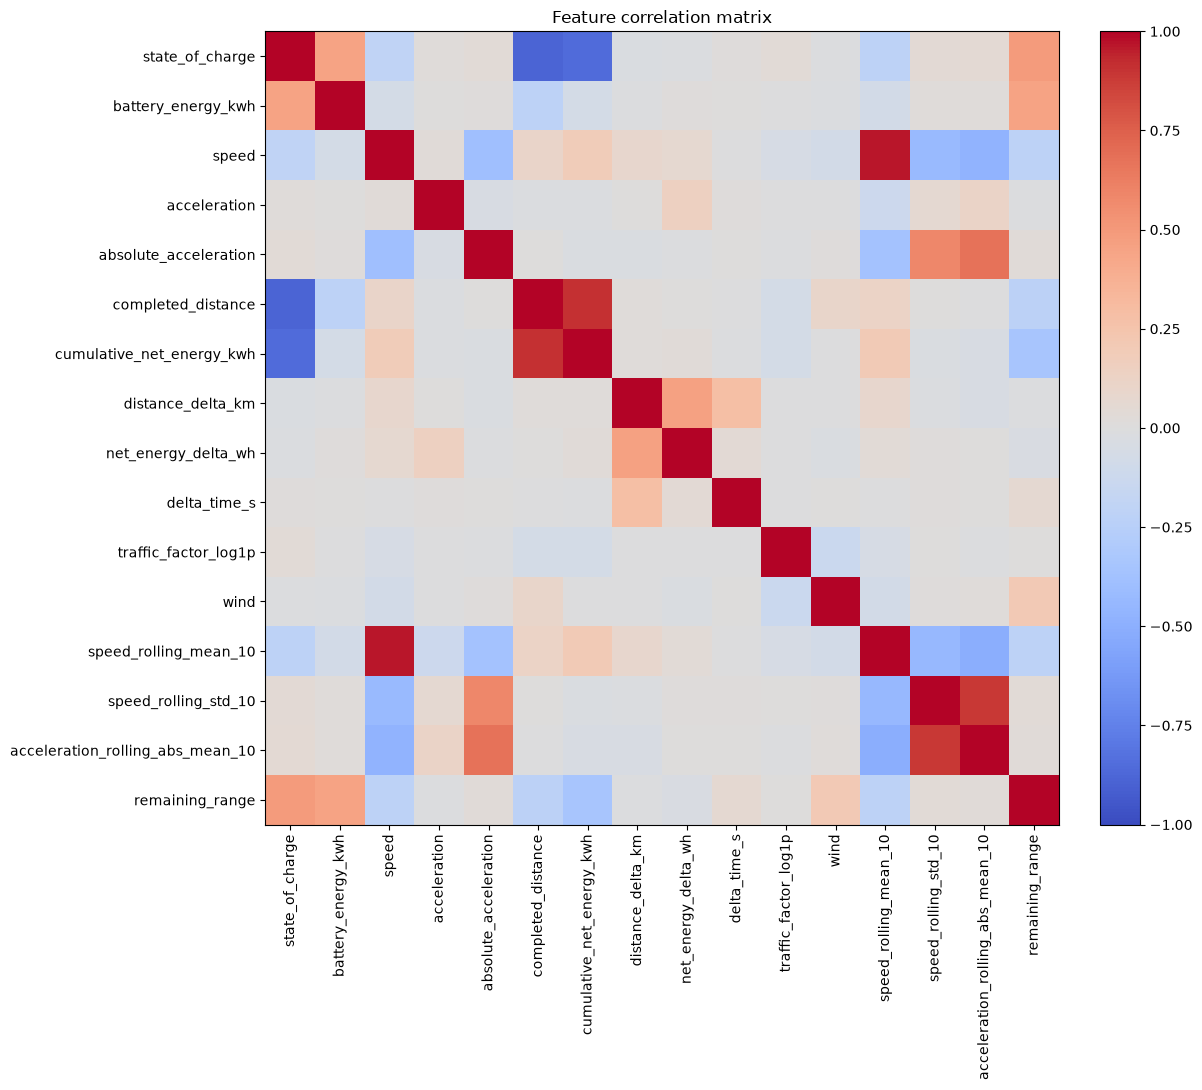

,correlation_with_target
remaining_range,1.000000
state_of_charge,0.484712
battery_energy_kwh,0.445437
wind,0.205277
delta_time_s,0.055529
speed_rolling_std_10,0.039052
absolute_acceleration,0.030604
acceleration_rolling_abs_mean_10,0.028097
traffic_factor_log1p,0.000516
distance_delta_km,-0.007939


In [7]:
FEATURE_COLUMNS = [
    "state_of_charge",
    "battery_energy_kwh",
    "speed",
    "acceleration",
    "absolute_acceleration",
    "completed_distance",
    "cumulative_net_energy_kwh",
    "distance_delta_km",
    "net_energy_delta_wh",
    "delta_time_s",
    "traffic_factor_log1p",
    "wind",
    "speed_rolling_mean_10",
    "speed_rolling_std_10",
    "acceleration_rolling_abs_mean_10",
]

correlation = telemetry[FEATURE_COLUMNS + [TARGET_COLUMN]].corr()
fig, axis = plt.subplots(figsize=(13, 11))
image = axis.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
axis.set_xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
axis.set_yticks(range(len(correlation.index)), correlation.index)
axis.set_title("Feature correlation matrix")
fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()
display(correlation[TARGET_COLUMN].sort_values(ascending=False).to_frame("correlation_with_target"))

## Leakage-safe trip split and LSTM sequences

A sequence contains the previous 30 observations from exactly one vehicle trip. Vehicle and route identifiers are used only to maintain boundaries; they are not model inputs. Scalers are fitted on training rows only.

In [8]:
trip_groups = telemetry[GROUP_COLUMNS].drop_duplicates().reset_index(drop=True)
train_groups, holdout_groups = train_test_split(
    trip_groups, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)
validation_groups, test_groups = train_test_split(
    holdout_groups, test_size=0.50, random_state=RANDOM_STATE, shuffle=True
)

def select_group_rows(frame: pd.DataFrame, groups: pd.DataFrame) -> pd.DataFrame:
    return frame.merge(groups, on=GROUP_COLUMNS, how="inner", validate="many_to_one")

train_rows = select_group_rows(telemetry, train_groups)
validation_rows = select_group_rows(telemetry, validation_groups)
test_rows = select_group_rows(telemetry, test_groups)

train_key_set = set(map(tuple, train_groups.to_numpy()))
validation_key_set = set(map(tuple, validation_groups.to_numpy()))
test_key_set = set(map(tuple, test_groups.to_numpy()))
assert train_key_set.isdisjoint(validation_key_set)
assert train_key_set.isdisjoint(test_key_set)
assert validation_key_set.isdisjoint(test_key_set)

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "trips": [len(train_groups), len(validation_groups), len(test_groups)],
    "telemetry_rows": [len(train_rows), len(validation_rows), len(test_rows)],
})
display(split_summary)

,split,trips,telemetry_rows
0,train,220,430809
1,validation,47,104093
2,test,48,95304


In [9]:
feature_scaler = StandardScaler()
target_scaler = StandardScaler()
feature_scaler.fit(train_rows[FEATURE_COLUMNS])
target_scaler.fit(train_rows[[TARGET_COLUMN]])

def build_sequences(
    frame: pd.DataFrame,
    *,
    maximum_sequences: int | None,
) -> tuple[np.ndarray, np.ndarray, pd.DataFrame]:
    sequences = []
    targets = []
    metadata = []

    for (vehicle_id, trip_plan), trip in frame.groupby(
        GROUP_COLUMNS, sort=False, observed=True
    ):
        trip = trip.sort_values("simulation_step")
        if len(trip) < SEQUENCE_LENGTH:
            continue
        features = feature_scaler.transform(trip[FEATURE_COLUMNS]).astype(np.float32)
        target = target_scaler.transform(trip[[TARGET_COLUMN]]).ravel().astype(np.float32)

        for end_index in range(SEQUENCE_LENGTH - 1, len(trip), SEQUENCE_STRIDE):
            start_index = end_index - SEQUENCE_LENGTH + 1
            sequences.append(features[start_index:end_index + 1])
            targets.append(target[end_index])
            metadata.append({
                "vehicle_id": vehicle_id,
                "trip_plan": trip_plan,
                "simulation_step": float(trip.iloc[end_index]["simulation_step"]),
            })

    X = np.asarray(sequences, dtype=np.float32)
    y = np.asarray(targets, dtype=np.float32)
    sequence_metadata = pd.DataFrame(metadata)

    if maximum_sequences is not None and len(X) > maximum_sequences:
        generator = np.random.default_rng(RANDOM_STATE)
        selected = np.sort(generator.choice(len(X), maximum_sequences, replace=False))
        X = X[selected]
        y = y[selected]
        sequence_metadata = sequence_metadata.iloc[selected].reset_index(drop=True)

    return X, y, sequence_metadata

X_train, y_train, train_metadata = build_sequences(
    train_rows, maximum_sequences=MAX_TRAIN_SEQUENCES
)
X_validation, y_validation, validation_metadata = build_sequences(
    validation_rows, maximum_sequences=MAX_EVALUATION_SEQUENCES
)
X_test, y_test, test_metadata = build_sequences(
    test_rows, maximum_sequences=MAX_EVALUATION_SEQUENCES
)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_validation:", X_validation.shape, "y_validation:", y_validation.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)
assert X_train.shape[1:] == (SEQUENCE_LENGTH, len(FEATURE_COLUMNS))

X_train: (84978, 30, 15) y_train: (84978,)
X_validation: (20564, 30, 15) y_validation: (20564,)
X_test: (18800, 30, 15) y_test: (18800,)


## LSTM model training

In [10]:
try:
    import tensorflow as tf
except ImportError as error:
    raise ImportError(
        "TensorFlow is not installed in this notebook kernel. In Anaconda Prompt, "
        "run: conda activate llm-env, then: pip install tensorflow"
    ) from error

tf.keras.utils.set_random_seed(RANDOM_STATE)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [11]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(SEQUENCE_LENGTH, len(FEATURE_COLUMNS))),
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.Dropout(0.20),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dropout(0.20),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1),
])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.Huber(),
    metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae_scaled")],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,985 (132.75 KB)

 Trainable params: 33,985 (132.75 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
MODEL_DIRECTORY = (
    PROJECT_ROOT / "ev_battery_prediction" / "data"
    / "model_data" / "campaign1_lstm"
)
MODEL_DIRECTORY.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = MODEL_DIRECTORY / "best_campaign1_lstm.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH, monitor="val_loss", save_best_only=True
    ),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_validation, y_validation),
    epochs=50,
    batch_size=256,
    callbacks=callbacks,
    shuffle=True,
    verbose=2,
)

Epoch 1/50
332/332 - 23s - 68ms/step - loss: 0.0710 - mae_scaled: 0.2221 - val_loss: 0.0304 - val_mae_scaled: 0.1150 - learning_rate: 0.0010
Epoch 2/50
332/332 - 21s - 63ms/step - loss: 0.0319 - mae_scaled: 0.1395 - val_loss: 0.0172 - val_mae_scaled: 0.0828 - learning_rate: 0.0010
Epoch 3/50
332/332 - 22s - 66ms/step - loss: 0.0268 - mae_scaled: 0.1240 - val_loss: 0.0172 - val_mae_scaled: 0.0888 - learning_rate: 0.0010
Epoch 4/50
332/332 - 20s - 61ms/step - loss: 0.0238 - mae_scaled: 0.1155 - val_loss: 0.0212 - val_mae_scaled: 0.1002 - learning_rate: 0.0010
Epoch 5/50
332/332 - 21s - 62ms/step - loss: 0.0211 - mae_scaled: 0.1074 - val_loss: 0.0148 - val_mae_scaled: 0.0907 - learning_rate: 0.0010
Epoch 6/50
332/332 - 47s - 141ms/step - loss: 0.0192 - mae_scaled: 0.1016 - val_loss: 0.0146 - val_mae_scaled: 0.0925 - learning_rate: 0.0010
Epoch 7/50
332/332 - 41s - 122ms/step - loss: 0.0186 - mae_scaled: 0.0992 - val_loss: 0.0156 - val_mae_scaled: 0.0969 - learning_rate: 0.0010
Epoch 8/50


,loss,mae_scaled,val_loss,val_mae_scaled,learning_rate
epoch,,,,,
17,0.008153,0.061893,0.013371,0.124774,0.000250
18,0.007865,0.060988,0.014287,0.127970,0.000250
19,0.007058,0.057348,0.013308,0.124357,0.000125
20,0.006862,0.056356,0.014373,0.129987,0.000125
21,0.006913,0.056533,0.013785,0.128336,0.000125


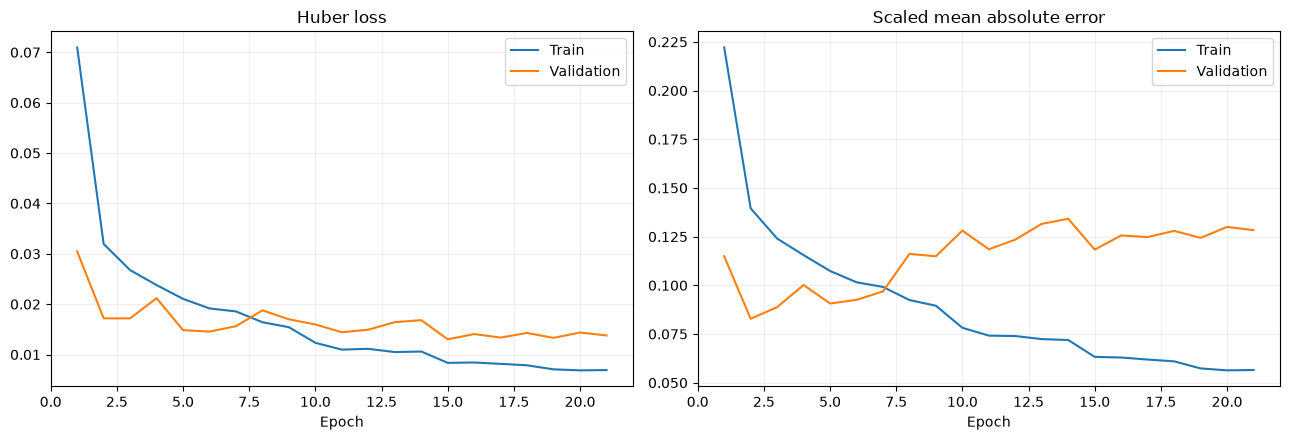

In [13]:
history_frame = pd.DataFrame(history.history)
history_frame.index = history_frame.index + 1
history_frame.index.name = "epoch"
display(history_frame.tail())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history_frame.index, history_frame["loss"], label="Train")
axes[0].plot(history_frame.index, history_frame["val_loss"], label="Validation")
axes[0].set_title("Huber loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.2)
axes[1].plot(history_frame.index, history_frame["mae_scaled"], label="Train")
axes[1].plot(history_frame.index, history_frame["val_mae_scaled"], label="Validation")
axes[1].set_title("Scaled mean absolute error")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Test evaluation in kilometres

In [14]:
predicted_scaled = model.predict(X_test, batch_size=512, verbose=0)
predicted_range_km = target_scaler.inverse_transform(predicted_scaled).ravel()
actual_range_km = target_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
predicted_range_km = np.clip(predicted_range_km, 0, None)

mae_km = mean_absolute_error(actual_range_km, predicted_range_km)
rmse_km = mean_squared_error(actual_range_km, predicted_range_km) ** 0.5
r2 = r2_score(actual_range_km, predicted_range_km)
nonzero = actual_range_km > 1.0
mape_percent = np.mean(
    np.abs((actual_range_km[nonzero] - predicted_range_km[nonzero])
           / actual_range_km[nonzero])
) * 100

metrics = pd.DataFrame({
    "metric": ["MAE (km)", "RMSE (km)", "R²", "MAPE (%)"],
    "value": [mae_km, rmse_km, r2, mape_percent],
})
display(metrics)

predictions = test_metadata.copy()
predictions["actual_remaining_range_km"] = actual_range_km
predictions["predicted_remaining_range_km"] = predicted_range_km
predictions["absolute_error_km"] = np.abs(actual_range_km - predicted_range_km)
display(predictions.head(20))

,metric,value
0,MAE (km),15.239508
1,RMSE (km),21.255723
2,R²,0.972813
3,MAPE (%),10.646243


,vehicle_id,trip_plan,simulation_step,actual_remaining_range_km,predicted_remaining_range_km,absolute_error_km
0,EV0,bilbao-vitoria,130.0,95.209572,141.746521,46.536949
1,EV0,bilbao-vitoria,135.0,109.587685,141.569580,31.981895
2,EV0,bilbao-vitoria,140.0,95.526108,126.267982,30.741875
3,EV0,bilbao-vitoria,145.0,128.333496,150.740692,22.407196
4,EV0,bilbao-vitoria,150.0,125.612022,146.998199,21.386177
5,EV0,bilbao-vitoria,155.0,132.380707,169.532974,37.152267
6,EV0,bilbao-vitoria,160.0,139.261597,169.303787,30.042191
7,EV0,bilbao-vitoria,165.0,122.959419,143.143127,20.183708
8,EV0,bilbao-vitoria,170.0,143.614166,145.421234,1.807068
9,EV0,bilbao-vitoria,175.0,181.123703,182.644714,1.521011


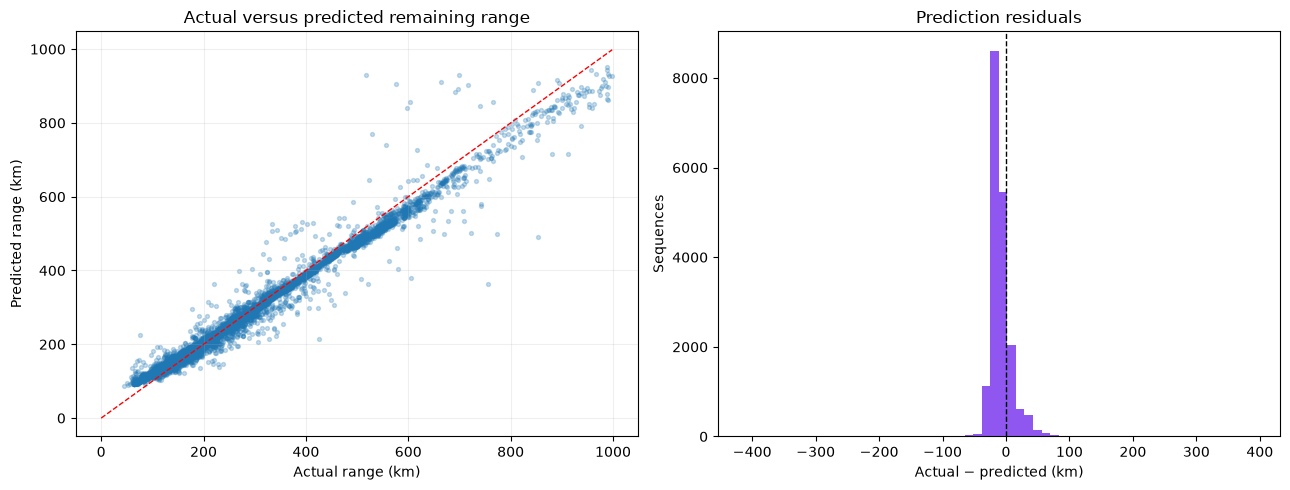

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(actual_range_km, predicted_range_km, s=8, alpha=0.25)
limit = max(float(actual_range_km.max()), float(predicted_range_km.max()))
axes[0].plot([0, limit], [0, limit], "r--", linewidth=1)
axes[0].set_title("Actual versus predicted remaining range")
axes[0].set_xlabel("Actual range (km)")
axes[0].set_ylabel("Predicted range (km)")
axes[0].grid(alpha=0.2)

residuals = actual_range_km - predicted_range_km
axes[1].hist(residuals, bins=60, color="#7c3aed", alpha=0.85)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Prediction residuals")
axes[1].set_xlabel("Actual − predicted (km)")
axes[1].set_ylabel("Sequences")
plt.tight_layout()
plt.show()

In [16]:
FINAL_MODEL_PATH = MODEL_DIRECTORY / "campaign1_lstm.keras"
model.save(FINAL_MODEL_PATH)
joblib.dump(feature_scaler, MODEL_DIRECTORY / "feature_scaler.joblib")
joblib.dump(target_scaler, MODEL_DIRECTORY / "target_scaler.joblib")
history_frame.to_csv(MODEL_DIRECTORY / "training_history.csv")
metrics.to_csv(MODEL_DIRECTORY / "test_metrics.csv", index=False)
predictions.to_parquet(MODEL_DIRECTORY / "test_predictions.parquet", index=False)

metadata = {
    "target": TARGET_COLUMN,
    "features": FEATURE_COLUMNS,
    "sequence_length": SEQUENCE_LENGTH,
    "sequence_stride": SEQUENCE_STRIDE,
    "maximum_reasonable_range_km": MAX_REASONABLE_RANGE_KM,
    "random_state": RANDOM_STATE,
    "split_unit": GROUP_COLUMNS,
}
with (MODEL_DIRECTORY / "metadata.json").open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print(f"Saved model and preprocessing artifacts to: {MODEL_DIRECTORY}")

Saved model and preprocessing artifacts to: C:\Users\Yessine\Desktop\vehicle_ai_copilote\ev_battery_prediction\data\model_data\campaign1_lstm


In [17]:
# Example prediction using the final 30 observations of one test trip.
example_group = test_rows[GROUP_COLUMNS].drop_duplicates().iloc[0]
example_trip = test_rows.loc[
    (test_rows["vehicle_id"] == example_group["vehicle_id"])
    & (test_rows["trip_plan"] == example_group["trip_plan"])
].sort_values("simulation_step")

example_features = feature_scaler.transform(
    example_trip[FEATURE_COLUMNS].tail(SEQUENCE_LENGTH)
).astype(np.float32)
example_scaled_prediction = model.predict(
    example_features[np.newaxis, ...], verbose=0
)
example_prediction_km = float(
    target_scaler.inverse_transform(example_scaled_prediction)[0, 0]
)

print("Vehicle:", example_group["vehicle_id"])
print("Trip:", example_group["trip_plan"])
print("Actual remaining range (km):", round(float(example_trip[TARGET_COLUMN].iloc[-1]), 2))
print("Predicted remaining range (km):", round(max(example_prediction_km, 0.0), 2))

Vehicle: EV0
Trip: bilbao-vitoria
Actual remaining range (km): 105.11
Predicted remaining range (km): 126.73


## Verified training result

The pipeline was executed in `llm-env` with TensorFlow 2.21.0. Early stopping finished after 21 epochs and restored the best validation weights. On 18,800 sequences from held-out vehicle trips, the model achieved:

- MAE: **15.24 km**
- RMSE: **21.26 km**
- R²: **0.9728**
- MAPE: **10.65%**

These are experimental results from simulated Campaign 1 data. They do not establish accuracy for a real BMW i3 without vehicle-specific validation.